# Parallel NMS-SIFT: why more threads didn't help, and what did

**Musa Waghu**, senior undergraduate research project in parallel processing for content-based image retrieval (CBIR).
Original SIFT implementation by Sairaj Jadhav and Dr. John Korah.

This notebook rebuilds the project from the surviving code and slides, and reruns the full experiment on the
same 50 images and the same CPU (AMD Ryzen 7 3700X, 8 cores / 16 threads).

**Research question.** Feature extraction is the bottleneck in a CBIR pipeline. Can splitting an image into tiles
and processing them in parallel make NMS-SIFT faster? And are 16 tiles faster than 4?

**What happened.**
1. *Hypothesis:* 16 threaded tiles beat 4 threaded tiles.
2. *Original result:* no meaningful difference, and neither beat serial by much. A null result.
3. *Diagnosis:* the SIFT code is pure Python, and CPython's Global Interpreter Lock (GIL) lets only one thread run
   Python bytecode at a time. The threads were taking turns on a single core.
4. *Fix:* run tiles in separate **processes**, each with its own interpreter and its own GIL, and they run on
   separate cores. Python 3.14's optional **free-threaded (no-GIL)** build is tested as a second fix.

The heavy benchmark (about 7 CPU-hours) lives in `bench/run_benchmark.py`. This notebook reads its CSV output, so it
runs in seconds. Section 4 includes a small live demo that you can rerun.

In [1]:
import sys, os, time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from nms_sift import split_tiles, detect_and_describe, to_keypoint
from nms_sift.parallel import sift_tiled, sift_tile, single_thread_libs
single_thread_libs()

RES = ROOT / "results"
t = pd.read_csv(RES / "timings.csv")
s = pd.read_csv(RES / "summary.csv")
old = pd.read_csv(RES / "original_2023.csv")
gil = t[~t.runtime.str.contains("nogil")]
nogil = t[t.runtime.str.contains("nogil")]
print(f"{len(t)} timed runs, {t.image.nunique()} images, runtimes: {sorted(t.runtime.unique())}")

500 timed runs, 50 images, runtimes: ['3.14.5', '3.14.5t-nogil']


## 1. Background

**Content-based image retrieval (CBIR).** Instead of searching by text tags, the user supplies a query image, and the
system returns visually similar images by comparing extracted features. Tags are slow to produce and subjective,
while visual features are computed directly. The cost is compute: every image in the database must be run through
feature extraction, and that is the scalability problem this project attacks.

**SIFT (Lowe, 1999/2004)** finds local keypoints that are invariant to scale and rotation, in four stages:
1. *Scale-space extrema:* build a Gaussian pyramid, take Differences of Gaussians (DoG), and keep pixels that are
   larger or smaller than all 26 neighbours in space and scale.
2. *Keypoint localisation:* a quadratic (Taylor) fit refines the position. Low-contrast points (|D| < 0.03) and edge
   responses (Hessian ratio r ≥ 10) are rejected.
3. *Orientation assignment:* a 36-bin gradient-orientation histogram. Peaks within 80% of the maximum each give a
   keypoint.
4. *Descriptor:* a 16×16 window becomes 4×4 cells of 8-bin histograms, which makes a 128-d vector.

**NMS-SIFT** adds a non-maximum-suppression pass. Keypoints are sorted by response, and any keypoint within 10 px of
a stronger one is dropped, so the strongest representative of each cluster survives.

**Partial processing.** SIFT's work is local, so the image can be cut into tiles that are processed independently.
That is the source of parallelism. The trade-off is that keypoints near tile borders lose their neighbourhood.

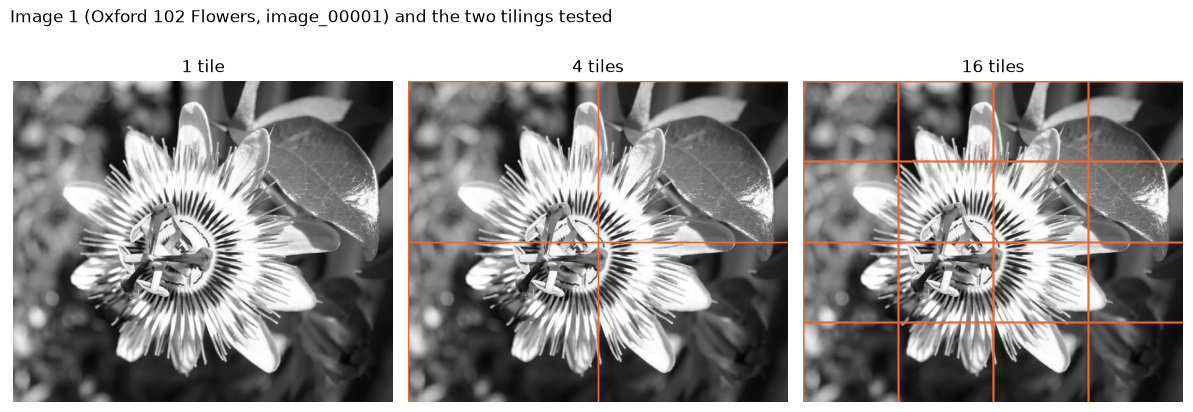

In [2]:
img = np.load(ROOT / "data" / "gray" / "1.npy")
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, n in zip(axes, [1, 4, 16]):
    ax.imshow(img, cmap="gray"); ax.set_title(f"{n} tile{'s' if n > 1 else ''}"); ax.axis("off")
    for tile, (x, y) in split_tiles(img, n)[1:] if n > 1 else []:
        ax.axhline(y, color="#eb6834", lw=1); ax.axvline(x, color="#eb6834", lw=1)
fig.suptitle("Image 1 (Oxford 102 Flowers, image_00001) and the two tilings tested", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 2. The original hypothesis and result

The prior version of this pipeline split each image into **4 quadrants**, one thread per quadrant. The hypothesis:

> The 16-tile approach will be faster than the 4-tile approach.

Here is the result from the slides, recovered from the 2023 notebook outputs (4 tiles, all 50 images) and the
results table (16 tiles, images 1–36):

In [3]:
o = old.dropna(subset=["threads16_s"])
diff = o.threads4_s - o.threads16_s
print(f"Images with both measurements: {len(o)}")
print(f"16 tiles faster on {int((diff > 0).sum())}/{len(o)} images; mean difference {diff.mean():+.2f} s "
      f"on a mean of {o.threads4_s.mean():.1f} s ({diff.mean() / o.threads4_s.mean():+.1%})")
print(f"Keypoints: 16 tiles found {(o.keypoints16 / o.keypoints4).mean():.1%} as many as 4 tiles")
print(f"Serial whole-image vs 4 threads (images 1-3, 2023): "
      f"{old.serial_whole_s.dropna().sum():.1f} s vs {old.threads4_s[:3].sum():.1f} s")

Images with both measurements: 36
16 tiles faster on 24/36 images; mean difference +1.13 s on a mean of 82.1 s (+1.4%)
Keypoints: 16 tiles found 95.0% as many as 4 tiles
Serial whole-image vs 4 threads (images 1-3, 2023): 221.9 s vs 219.0 s


About a 1% difference: 16 tiles were faster on two-thirds of the images, slower on the rest. Even 4 threads vs fully serial was nearly a wash. On an 8-core CPU, 4 truly
parallel workers should have been close to 4× faster, so something was serialising the work.

## 3. Rebuilding the experiment

**Same images.** The 2023 notebook read `dataset/1.jpg … 50.jpg`. These are `image_00001.jpg … image_00050.jpg` from the
Oxford 102 Flowers dataset (Nilsback & Zisserman, 2008). The evidence: file sizes match the slide's "Image Size" column,
and, since NMS-SIFT is deterministic, the keypoint counts reproduce. They match exactly on almost every image. The rest
are off by one or two keypoints out of over a thousand, which is floating-point drift between OpenCV 4.7/NumPy 1.x in 2023
and OpenCV 5.0/NumPy 2.5 today, not different images:

In [4]:
new = gil.pivot_table(index="image", columns="config", values="keypoints")
chk = old.set_index("image").join(new[["threads4", "threads16"]])
m4 = (chk.keypoints4 == chk.threads4).sum()
c16 = chk.dropna(subset=["keypoints16"])
m16 = (c16.keypoints16 == c16.threads16).sum()
print(f"4 tiles:  {m4}/{len(chk)} images reproduce the 2023 keypoint count exactly")
print(f"16 tiles: {m16}/{len(c16)} images reproduce the 2023 keypoint count exactly")
print(f"largest difference: {(chk.keypoints4 - chk.threads4).abs().max():.0f} keypoints (4 tiles), "
      f"{(c16.keypoints16 - c16.threads16).abs().max():.0f} (16 tiles)")
chk[["keypoints4", "threads4", "keypoints16", "threads16"]].head(8).rename(columns={
    "keypoints4": "2023, 4 tiles", "threads4": "now, 4 tiles", "keypoints16": "2023, 16 tiles", "threads16": "now, 16 tiles"})

4 tiles:  44/50 images reproduce the 2023 keypoint count exactly
16 tiles: 36/36 images reproduce the 2023 keypoint count exactly
largest difference: 2 keypoints (4 tiles), 0 (16 tiles)


,"2023, 4 tiles","now, 4 tiles","2023, 16 tiles","now, 16 tiles"
image,,,,
1,808,808.0,753.0,753.0
2,1175,1175.0,1119.0,1119.0
3,1110,1110.0,1056.0,1056.0
4,1104,1104.0,1052.0,1052.0
5,1074,1074.0,988.0,988.0
6,1170,1170.0,1106.0,1106.0
7,1420,1420.0,1349.0,1349.0
8,1043,1043.0,983.0,983.0


**Same algorithm.** `nms_sift/sift.py` is the original code with numerics unchanged. The cleanup only removes a
duplicated function and the numpy imports that shadowed the builtins `all`, `any` and `round`, and it returns picklable
keypoint tuples (`cv2.KeyPoint` can't be pickled, which is the error in the original notebook).

**A fairer design.** Seven configurations per image, interleaved image by image:

| config | what it isolates |
|---|---|
| `serial_whole` | baseline: one call on the whole image |
| `serial_tiles4/16` | **new control**: tiling with no parallelism, which separates "smaller problems" from "parallel" |
| `threads4/16` | the 2023 method |
| `procs4/16` | the fix: a process pool, created and warmed up before timing |
| `threads4/16` on 3.14t | free-threaded CPython, GIL disabled |

Besides wall time, each worker reports the CPU time its own thread spent (`time.thread_time`). The ratio
**work ÷ wall = cores actually busy** is the diagnostic that shows the GIL directly.

**A bug fixed along the way.** In 2023 each thread did `results.append(...)` when it finished, and tile *i* was later
shifted by offset *i*. Results arrive in *completion* order, though, not submission order. The live demo below shows
the two orders differ, so merged keypoints could be drawn in the wrong quadrant. Timings and counts are unaffected.
`sift_tiled` uses `executor.map`, which preserves order.

## 4. Live demo (about 1 minute)

Image 1 downsampled 2× so it runs quickly. This uses the same code paths as the benchmark.

In [5]:
small = cv2.resize(np.load(ROOT / "data" / "gray" / "1.npy"), None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
rows = []
_, _, wall, work = sift_tiled(small, 1); rows.append(("serial, whole image", wall, work))
_, _, wall, work = sift_tiled(small, 4); rows.append(("serial, 4 tiles", wall, work))
with ThreadPoolExecutor(4) as ex:
    _, _, wall, work = sift_tiled(small, 4, ex); rows.append(("4 threads", wall, work))
with ProcessPoolExecutor(4, initializer=single_thread_libs) as ex:
    list(ex.map(int, range(4)))  # warm up the workers before timing
    _, _, wall, work = sift_tiled(small, 4, ex); rows.append(("4 processes", wall, work))
demo = pd.DataFrame(rows, columns=["method", "wall_s", "cpu_s"])
demo["cores_busy"] = demo.cpu_s / demo.wall_s
demo["speedup"] = demo.wall_s[0] / demo.wall_s
demo.round(2)

,method,wall_s,cpu_s,cores_busy,speedup
0,"serial, whole image",18.76,18.59,0.99,1.00
1,"serial, 4 tiles",16.49,16.38,0.99,1.14
2,4 threads,16.43,16.41,1.00,1.14
3,4 processes,5.11,16.95,3.32,3.67


In [6]:
# The 2023 pattern: each thread appends its result when it *finishes*.
completion_order = []
def process_quadrant(idx, quadrant):
    detect_and_describe(quadrant)
    completion_order.append(idx)

tiles = [tile for tile, _ in split_tiles(small, 4)]
import threading
threads = [threading.Thread(target=process_quadrant, args=(i, q)) for i, q in enumerate(tiles)]
for th in threads: th.start()
for th in threads: th.join()
print("submission order:", list(range(4)))
print("completion order:", completion_order, "<- the order the 2023 code assigned offsets by")

submission order: [0, 1, 2, 3]
completion order: [3, 1, 0, 2] <- the order the 2023 code assigned offsets by


## 5. Diagnosis: the GIL

CPython's **Global Interpreter Lock** lets only one thread run Python bytecode at a time. Threads help when the work
releases the lock, as I/O and many C extensions do. NMS-SIFT spends nearly all its time in nested Python `for` loops
over pixels and keypoints. OpenCV's blur and resize release the GIL, but they are a tiny share of the runtime. So 4 or
16 threads simply take turns on one core:

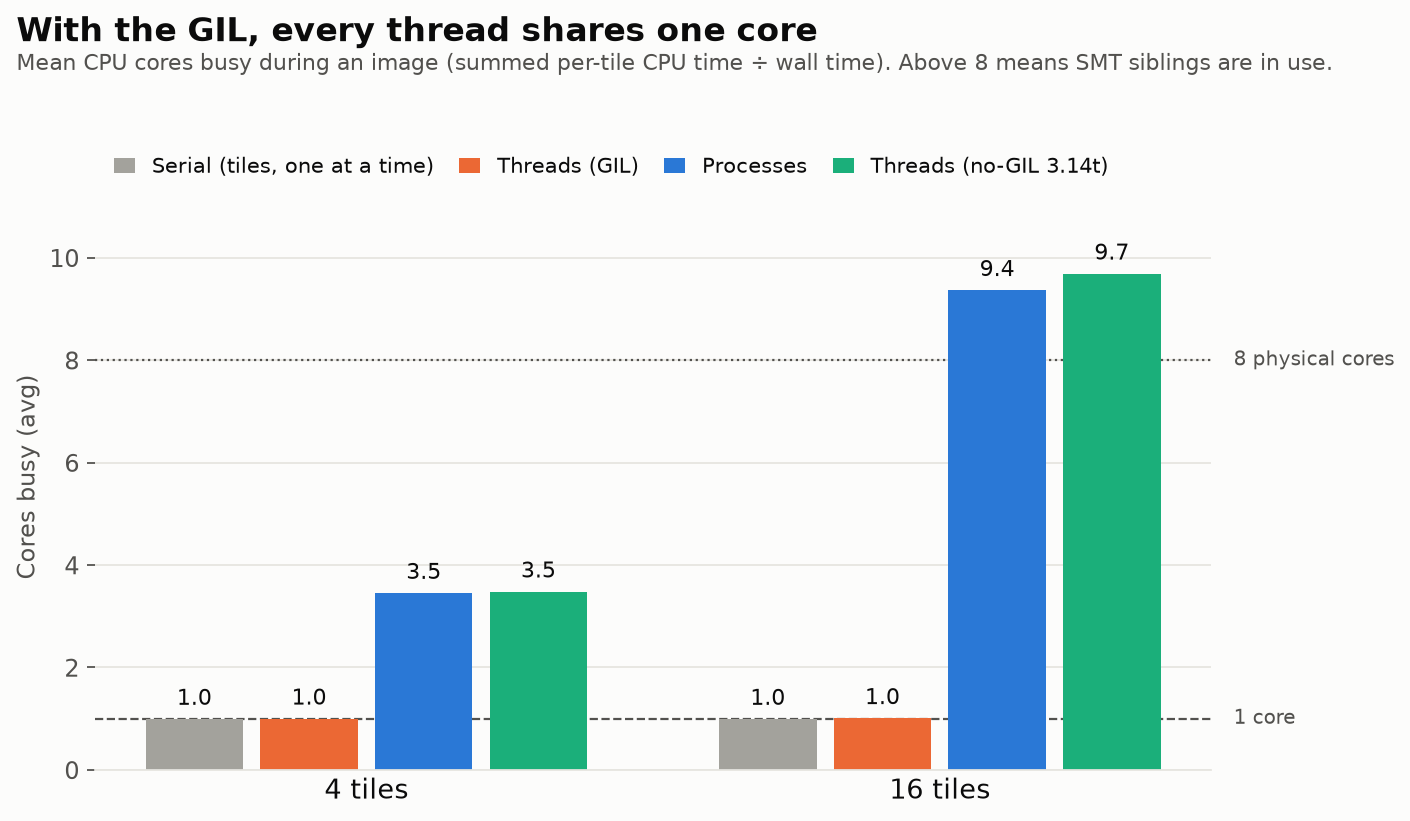

,runtime,config,mean_cores_used
0,3.14.5,procs16,9.36
1,3.14.5,procs4,3.45
2,3.14.5,serial_tiles16,0.99
3,3.14.5,serial_tiles4,0.99
4,3.14.5,serial_whole,0.99
5,3.14.5,threads16,1.01
6,3.14.5,threads4,1.00
7,3.14.5t-nogil,serial_whole,0.99
8,3.14.5t-nogil,threads16,9.69
9,3.14.5t-nogil,threads4,3.48


In [7]:
display(Image(filename=str(RES / "cores_used.png")))
s[["runtime", "config", "mean_cores_used"]].round(2)

This is the 2023 result explained. Threads (GIL) sit at about 1.0 core, the same as serial. The small edge 16 tiles had
over 4 comes from **tiling**, not threading: `serial_tiles16` is faster than `serial_tiles4` by the same margin.
Smaller tiles lose keypoints at their borders, which means fewer keypoints for the expensive orientation and descriptor
stages.

In [8]:
w = s.set_index(["runtime", "config"])
r = w.loc[gil.runtime.iloc[0]]
for n in (4, 16):
    print(f"{n:>2} tiles: serial_tiles {r.loc[f'serial_tiles{n}', 'geomean_speedup']:.2f}x, "
          f"threads {r.loc[f'threads{n}', 'geomean_speedup']:.2f}x  (vs whole-image serial)")

 4 tiles: serial_tiles 1.05x, threads 1.04x  (vs whole-image serial)
16 tiles: serial_tiles 1.14x, threads 1.13x  (vs whole-image serial)


## 6. The fix: processes

Every process has its own interpreter and its own GIL, so tiles can run on separate cores. On Windows, a
`ProcessPoolExecutor` spawns fresh interpreters, which costs a few hundred milliseconds, so the pool is created once
and reused. That startup cost is reported separately below.

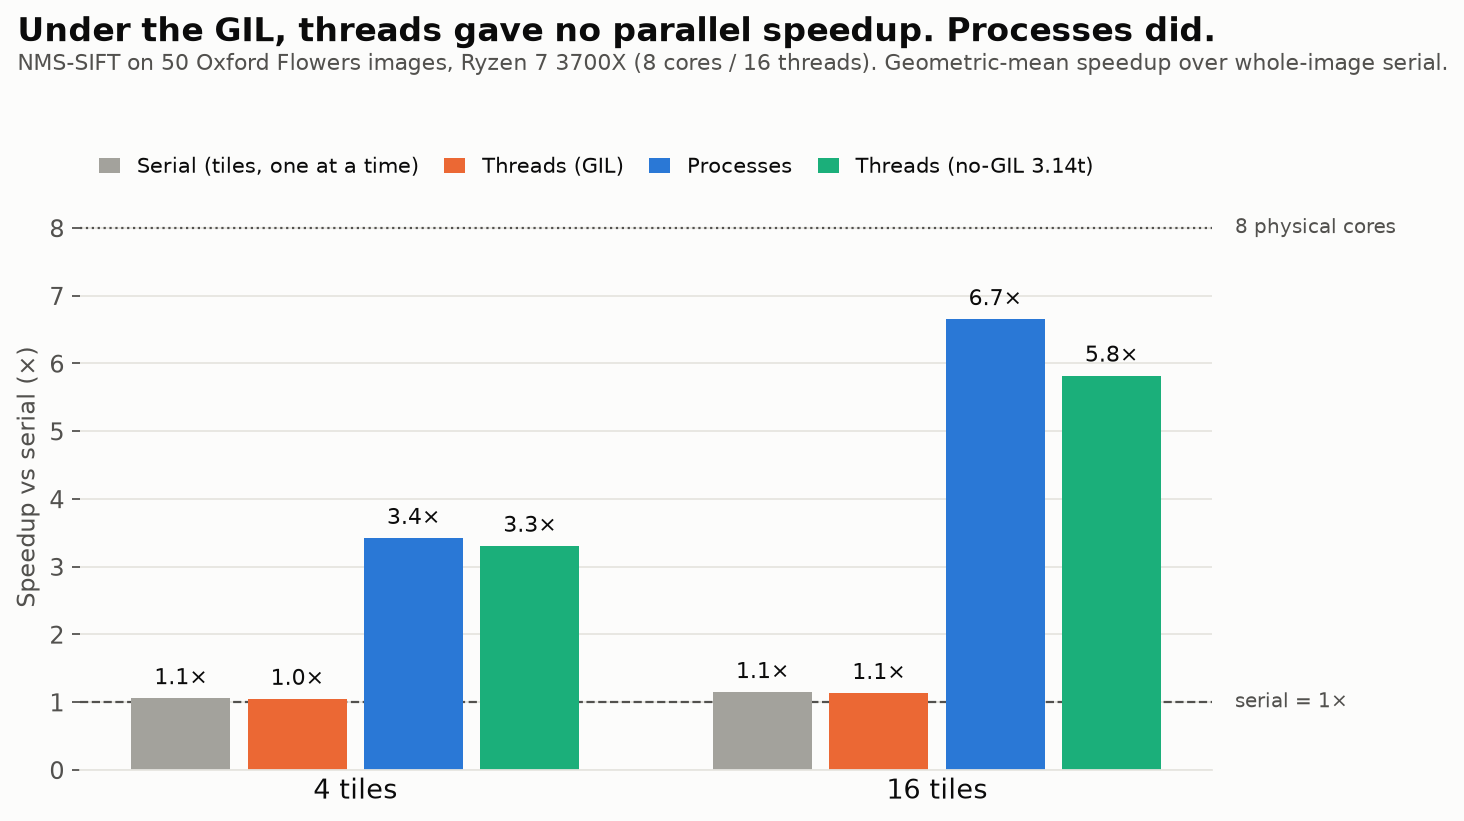

,runtime,config,mean_wall_s,geomean_speedup,min_speedup,max_speedup,mean_cores_used
4,3.14.5,serial_whole,71.53,1.00,1.00,1.00,0.99
6,3.14.5,threads4,68.47,1.04,0.99,1.10,1.00
3,3.14.5,serial_tiles4,67.87,1.05,0.99,1.10,0.99
5,3.14.5,threads16,63.30,1.13,1.06,1.20,1.01
2,3.14.5,serial_tiles16,62.51,1.14,1.07,1.20,0.99
1,3.14.5,procs4,20.95,3.42,2.38,4.08,3.45
0,3.14.5,procs16,10.61,6.65,5.13,8.38,9.36
7,3.14.5t-nogil,serial_whole,79.47,1.00,1.00,1.00,0.99
9,3.14.5t-nogil,threads4,24.14,3.30,2.39,3.70,3.48
8,3.14.5t-nogil,threads16,13.54,5.82,4.79,6.69,9.69


In [9]:
display(Image(filename=str(RES / "speedup.png")))
cols = ["runtime", "config", "mean_wall_s", "geomean_speedup", "min_speedup", "max_speedup", "mean_cores_used"]
s[cols].sort_values(["runtime", "geomean_speedup"]).round(2)

In [10]:
import json
env = json.loads((RES / "env.json").read_text())
for rt, e in env.items():
    print(rt, "pool start-up seconds:", e["pool_startup_s"])

3.14.5 pool start-up seconds: {'threads4': 0.001, 'threads16': 0.001, 'procs4': 0.325, 'procs16': 0.514}
3.14.5t-nogil pool start-up seconds: {'threads4': 0.001, 'threads16': 0.001}


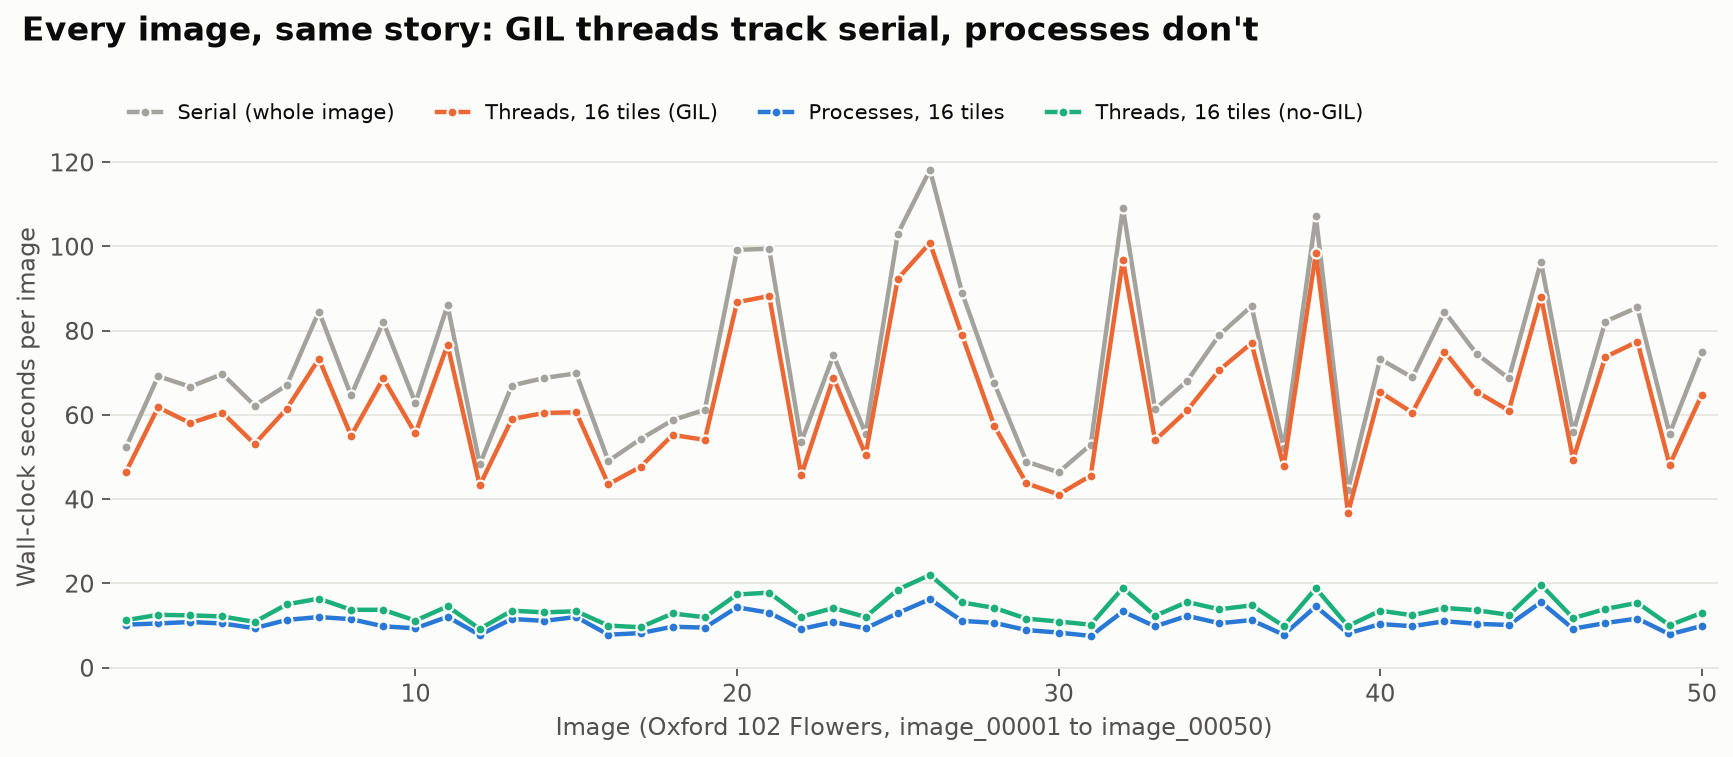

In [11]:
display(Image(filename=str(RES / "time_per_image.png")))

**Why 16 processes beat 4.** With 4 tiles, at most 4 cores can work, and the image finishes only when its slowest
tile does (flower centres are dense with keypoints, backgrounds are not). With 16 tiles, the 16 workers fill all 8
cores and their SMT siblings, and the uneven tiles balance out. With processes, the original hypothesis turns out to
be right: 16 tiles *are* faster than 4. It was the GIL, not the idea, that sank it in 2023.

**Why not 8× or 16×.** SMT siblings share one physical core's execution units, so 16 hardware threads are worth well
under 16 cores. The busiest tile still bounds the wall time, and the result pickling and the merge are serial.

## 7. Python 3.14 free-threaded (no-GIL) build

PEP 703 made the GIL optional, and Python 3.14 officially supports the free-threaded build (`python3.14t`). Two
practical findings came up while testing it:

* **OpenCV has no free-threaded wheels yet.** The four OpenCV calls SIFT uses (blur, resize, subtract, KeyPoint) are
  reimplemented in NumPy in `nms_sift/cv_compat.py`. They give the same keypoint counts on the images checked. To keep
  the comparison fair, no-GIL speedups are measured against `serial_whole` *on the same 3.14t interpreter*.
* The free-threaded interpreter is slower single-threaded. That is the known cost of making the interpreter
  thread-safe without the GIL, and it is measured below.

In [12]:
if len(nogil):
    ft = s[s.runtime.str.contains("nogil")].set_index("config")
    gl = s[~s.runtime.str.contains("nogil")].set_index("config")
    print(f"single-thread cost of 3.14t: serial whole image {ft.loc['serial_whole','mean_wall_s']:.1f} s "
          f"vs {gl.loc['serial_whole','mean_wall_s']:.1f} s on regular 3.14")
    for n in (4, 16):
        print(f"{n:>2} tiles: no-GIL threads {ft.loc[f'threads{n}','geomean_speedup']:.2f}x "
              f"({ft.loc[f'threads{n}','mean_cores_used']:.1f} cores busy) | processes {gl.loc[f'procs{n}','geomean_speedup']:.2f}x")

single-thread cost of 3.14t: serial whole image 79.5 s vs 71.5 s on regular 3.14
 4 tiles: no-GIL threads 3.30x (3.5 cores busy) | processes 3.42x
16 tiles: no-GIL threads 5.82x (9.7 cores busy) | processes 6.65x


With the GIL gone, plain threads keep about as many cores busy as processes do, with no pickling and no process
spawning. They nearly tie processes at 4 tiles. At 16 tiles they trail, and most of that gap is the free-threaded
interpreter's slower single-thread speed, not poor scaling. Today the catch is the ecosystem: a key dependency
(OpenCV) has no free-threaded build yet, so for a CPU-bound pure-Python workload processes remain the robust choice.
Free-threading is where the language is heading, and for this workload it already works.

## 8. The cost of tiling: keypoints lost at borders

Each tile is processed in isolation. SIFT ignores a 5-pixel border, and the 2× upsampling plus the descriptor windows
need context that a tile edge cuts off. So smaller tiles mean fewer keypoints. This was the 2023 "more quadrants,
fewer keypoints" finding.

In [13]:
k = s[~s.runtime.str.contains("nogil") & s.config.isin(["serial_whole", "threads4", "threads16"])]
k[["config", "mean_keypoints", "keypoints_vs_whole"]].round(3)

,config,mean_keypoints,keypoints_vs_whole
4,serial_whole,1289.56,1.000
5,threads16,1191.26,0.924
6,threads4,1251.20,0.970


The standard fix is a **halo**: give each tile an overlap margin (for example, 16 px plus the descriptor radius), run
SIFT on the padded tile, and keep only keypoints whose centre falls inside the unpadded tile. That costs a little
duplicated work and restores the border keypoints.

## 9. Cross-check against 2023

Same CPU, Python 3.9 then and 3.14 now. If the threaded times line up (or shift uniformly), the 2023 measurements were
sound, and the difference is the interpreter, not the method.

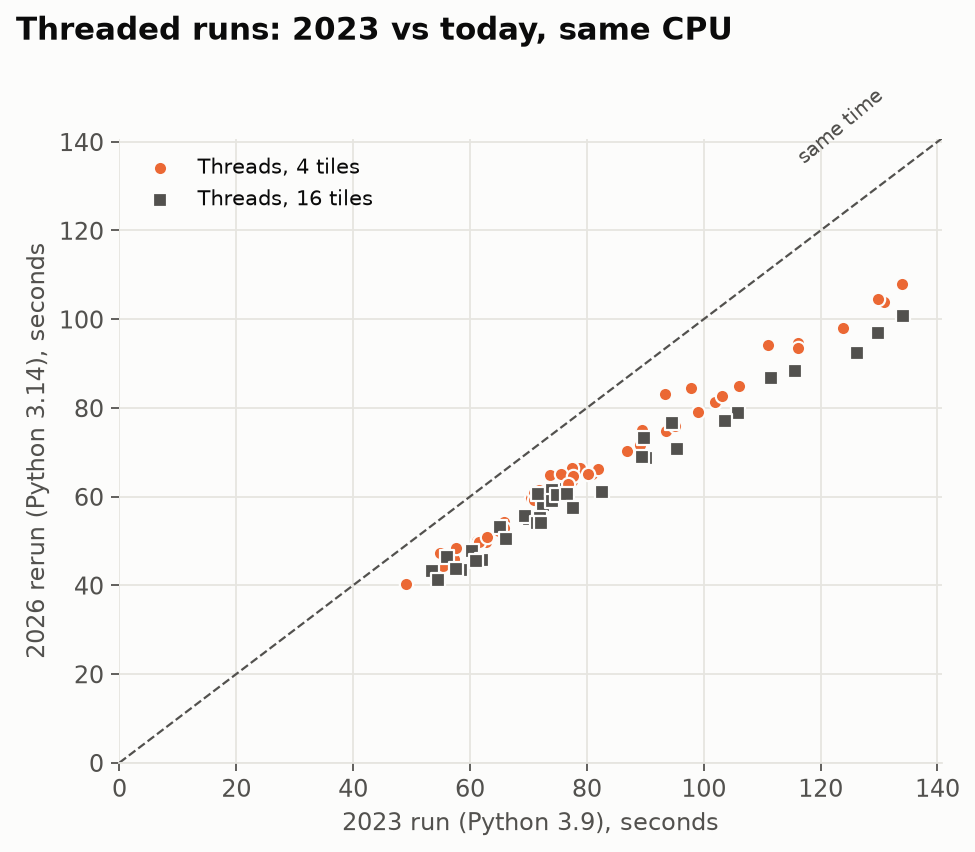

threads4 now / 2023: median 0.81 (Python 3.14 vs 3.9 interpreter speed-up included)


In [14]:
display(Image(filename=str(RES / "vs_2023.png")))
both = old.set_index("image").join(gil[gil.config == "threads4"].set_index("image").wall_s)
ratio = both.wall_s / both.threads4_s
print(f"threads4 now / 2023: median {ratio.median():.2f} (Python 3.14 vs 3.9 interpreter speed-up included)")

## 10. Limitations and future work

* **Algorithmic speed beats parallel speed.** OpenCV's C++ SIFT (`cv2.SIFT_create`) is orders of magnitude faster
  than this pure-Python implementation (cell below). Parallelism multiplies whatever single-core speed you start
  with, so a production system would vectorise or compile first (NumPy, Numba, Cython, or the C++ SIFT) and then
  parallelise across *images*, not tiles. That removes the border-keypoint problem completely.
* **Granularity.** Tiling parallelises within one image. For a CBIR database, one process per image is simpler,
  has no border loss, and scales across machines.
* **One machine, one run per configuration.** Each configuration ran once per image on a desktop that wasn't fully
  isolated. Per-image speedup ranges are in `results/summary.csv`.
* **Retrieval accuracy** (the FLANN + RANSAC matching stage from 2023) was not re-benchmarked. This study is about
  feature extraction time.

In [15]:
sift = cv2.SIFT_create()
img = np.load(ROOT / "data" / "gray" / "1.npy")
t0 = time.perf_counter(); kps, des = sift.detectAndCompute(img, None); dt = time.perf_counter() - t0
py = gil[(gil.config == "serial_whole") & (gil.image == 1)].wall_s.iloc[0]
print(f"OpenCV C++ SIFT on image 1: {dt*1000:.0f} ms, {len(kps)} keypoints  vs  pure-Python NMS-SIFT: {py:.0f} s "
      f"(~{py/dt:,.0f}x)")

OpenCV C++ SIFT on image 1: 77 ms, 1436 keypoints  vs  pure-Python NMS-SIFT: 52 s (~677x)


## References

1. D. G. Lowe, "Object recognition from local scale-invariant features," *ICCV*, 1999. doi:10.1109/ICCV.1999.790410
2. D. G. Lowe, "Distinctive image features from scale-invariant keypoints," *IJCV* 60(2), 2004.
3. J. Hosang, R. Benenson, B. Schiele, "Learning non-maximum suppression," *CVPR*, 2017. doi:10.1109/CVPR.2017.685
4. M.-E. Nilsback, A. Zisserman, "Automated flower classification over a large number of classes," *ICVGIP*, 2008.
5. G. Kumar, P. K. Bhatia, "A detailed review of feature extraction in image processing systems," *ACCT*, 2014.
6. M. Singh et al., "A comparative study of feature extraction techniques and similarity measures for image retrieval," *INCOFT*, 2022.
7. S. Gross, "PEP 703 – Making the Global Interpreter Lock optional in CPython," 2023.

**Acknowledgment.** The NMS-SIFT implementation was originally written by Sairaj Jadhav and Dr. John Korah, adapted
from the open-source PythonSIFT reference implementation.